# Late-Delivery Predictor for an E-commerce Marketplace
**NextGen Institute · Machine Learning Final Project**
Team: *[add names]* · Dataset: [Brazilian E-Commerce by Olist](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce)

**How to run:** download the Olist CSV files into a `data/` folder next to this notebook, then Restart & Run All.

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay,
                             average_precision_score, classification_report, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

RANDOM_STATE = 42
DATA_DIR = Path("data")
ART_DIR = Path("artifacts")
ART_DIR.mkdir(exist_ok=True)
TARGET_RECALL = 0.60  # business choice: catch at least 60% of late orders

## 1. Problem framing
- **Who has the problem:** an online marketplace connecting many small sellers with customers. Late deliveries create bad reviews and lost customers.
- **Decision supported:** at purchase time, flag risky orders so the company can warn the customer, push the carrier, or upgrade shipping.
- **Target:** `is_late = 1` if the order was delivered after its estimated delivery date (we build this label).
- **Metric that matters:** *recall* on the late class (missing a late order is costly) balanced with *precision* (too many false alarms waste effort). We track PR-AUC and ROC-AUC for model comparison, then pick a decision threshold for a target recall. Accuracy is misleading because late orders are a small minority.

## 2. Data understanding

In [2]:
def read(name):
    return pd.read_csv(DATA_DIR / name)


orders = read("olist_orders_dataset.csv")
items = read("olist_order_items_dataset.csv")
customers = read("olist_customers_dataset.csv")
sellers = read("olist_sellers_dataset.csv")
products = read("olist_products_dataset.csv")
payments = read("olist_order_payments_dataset.csv")
reviews = read("olist_order_reviews_dataset.csv")
translation = read("product_category_name_translation.csv")
geo = pd.read_csv(DATA_DIR / "olist_geolocation_dataset.csv", dtype={"geolocation_zip_code_prefix": str})

# zip prefixes are 5-digit codes: keep them as text with leading zeros so tables match
customers["customer_zip_code_prefix"] = customers["customer_zip_code_prefix"].astype(str).str.zfill(5)
sellers["seller_zip_code_prefix"] = sellers["seller_zip_code_prefix"].astype(str).str.zfill(5)

tables = {"orders": orders, "items": items, "customers": customers, "sellers": sellers, "products": products,
          "payments": payments, "reviews": reviews, "geolocation": geo, "translation": translation}
pd.DataFrame({name: {"rows": t.shape[0], "columns": t.shape[1], "missing cells": int(t.isna().sum().sum())}
              for name, t in tables.items()}).T

,rows,columns,missing cells
orders,99441,8,4908
items,112650,7,0
customers,99441,5,0
sellers,3095,4,0
products,32951,9,2448
payments,103886,5,0
reviews,99224,7,145903
geolocation,1000163,5,0
translation,71,2,0


**Column dictionary (tables we use)**

| Table | Key columns |
|---|---|
| orders | `order_id`, `customer_id`, `order_status`, purchase / approved / carrier / delivered / estimated-delivery timestamps |
| items | `order_id`, `product_id`, `seller_id`, `price`, `freight_value` |
| customers | `customer_id`, `customer_state`, `customer_zip_code_prefix` |
| sellers | `seller_id`, `seller_state` |
| products | `product_id`, category, weight, dimensions |
| payments | `order_id`, `payment_type`, `payment_installments`, `payment_value` |
| geolocation | `geolocation_zip_code_prefix`, latitude, longitude (about 1M rows, many per zip prefix) |
| reviews | review score (only used for the optional stretch goal, never as a feature) |

In [3]:
orders.info()
orders.order_status.value_counts()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

### Build the target
Only **delivered** orders with a delivery date can be labelled. We compare *dates* (not times): the estimate is a date, so an order delivered on the estimated day is on time.

In [4]:
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])

delivered = orders[(orders.order_status == "delivered") & orders.order_delivered_customer_date.notna()].copy()
delivered["is_late"] = (delivered.order_delivered_customer_date.dt.normalize()
                        > delivered.order_estimated_delivery_date.dt.normalize()).astype(int)
print(f"Labelled orders: {len(delivered):,}")
print(delivered.is_late.value_counts(normalize=True).rename("share"))

Labelled orders: 96,470
is_late
0    0.932269
1    0.067731
Name: share, dtype: float64


### Join the tables into one row per order (purchase-time information only)
**Leakage rules:** we do *not* use approval time, carrier handover date, delivered date, or review data as features, because none of them are known when the customer buys.

In [5]:
# products: English category names + volume
products = products.merge(translation, on="product_category_name", how="left")
products["product_category"] = (products.product_category_name_english
                                .fillna(products.product_category_name).fillna("unknown"))
products["product_volume_cm3"] = (products.product_length_cm * products.product_height_cm
                                  * products.product_width_cm)

items_p = items.merge(products[["product_id", "product_category", "product_weight_g", "product_volume_cm3"]],
                      on="product_id", how="left")

# items -> one row per order
order_items = items_p.groupby("order_id").agg(
    price=("price", "sum"),
    freight_value=("freight_value", "sum"),
    n_items=("order_item_id", "count"),
    n_sellers=("seller_id", "nunique"),
    seller_id=("seller_id", "first"),
    product_category=("product_category", "first"),
    product_weight_g=("product_weight_g", lambda s: s.sum(min_count=1)),
    product_volume_cm3=("product_volume_cm3", lambda s: s.sum(min_count=1)),
).reset_index()

# payments -> one row per order (type with the largest payment, max installments)
pay = (payments.sort_values("payment_value", ascending=False).groupby("order_id")
       .agg(payment_type=("payment_type", "first"), installments=("payment_installments", "max"))
       .reset_index())

# zip prefix -> coordinates: the geolocation table has many points per prefix, and a few are wrong
# (outside Brazil), so we drop those and take the median of the rest
geo_ok = geo[geo.geolocation_lat.between(-34, 6) & geo.geolocation_lng.between(-74, -34)]
print(f"geolocation rows: {len(geo):,}, outside Brazil dropped: {len(geo) - len(geo_ok):,}")
zip_coords = (geo_ok.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].median()
              .rename(columns={"geolocation_lat": "lat", "geolocation_lng": "lng"}))
print(f"zip prefixes with coordinates: {len(zip_coords):,}")

# fallback when a zip prefix has no coordinates: the coordinates of the state capital
STATE_CAPITALS = {
    "AC": (-9.97, -67.81), "AL": (-9.67, -35.74), "AM": (-3.12, -60.02), "AP": (0.03, -51.07),
    "BA": (-12.97, -38.51), "CE": (-3.73, -38.53), "DF": (-15.78, -47.93), "ES": (-20.32, -40.34),
    "GO": (-16.68, -49.25), "MA": (-2.53, -44.30), "MG": (-19.92, -43.94), "MS": (-20.47, -54.62),
    "MT": (-15.60, -56.10), "PA": (-1.46, -48.50), "PB": (-7.12, -34.86), "PE": (-8.05, -34.88),
    "PI": (-5.09, -42.80), "PR": (-25.43, -49.27), "RJ": (-22.91, -43.17), "RN": (-5.79, -35.21),
    "RO": (-8.76, -63.90), "RR": (2.82, -60.67), "RS": (-30.03, -51.23), "SC": (-27.59, -48.55),
    "SE": (-10.91, -37.07), "SP": (-23.55, -46.63), "TO": (-10.18, -48.33),
}
state_centroids = pd.DataFrame.from_dict(STATE_CAPITALS, orient="index", columns=["lat", "lng"])

df = (delivered
      .merge(order_items, on="order_id", how="inner")
      .merge(pay, on="order_id", how="left")
      .merge(customers[["customer_id", "customer_state", "customer_zip_code_prefix"]], on="customer_id", how="left")
      .merge(sellers[["seller_id", "seller_state", "seller_zip_code_prefix"]], on="seller_id", how="left"))


def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))


s = zip_coords.reindex(df.seller_zip_code_prefix).to_numpy()
c = zip_coords.reindex(df.customer_zip_code_prefix).to_numpy()
s_fb = state_centroids.reindex(df.seller_state).to_numpy()
c_fb = state_centroids.reindex(df.customer_state).to_numpy()
missing_s, missing_c = np.isnan(s[:, 0]), np.isnan(c[:, 0])
print(f"fallback to state capital: sellers {missing_s.mean():.2%}, customers {missing_c.mean():.2%} of orders")
s = np.where(missing_s[:, None], s_fb, s)
c = np.where(missing_c[:, None], c_fb, c)
df["distance_km"] = haversine_km(s[:, 0], s[:, 1], c[:, 0], c[:, 1])
df["same_state"] = (df.seller_state == df.customer_state).astype(int)
df["freight_ratio"] = df.freight_value / df.price.replace(0, np.nan)
df["est_delivery_days"] = (df.order_estimated_delivery_date - df.order_purchase_timestamp).dt.total_seconds() / 86400
df["purchase_month"] = df.order_purchase_timestamp.dt.month
df["purchase_dow"] = df.order_purchase_timestamp.dt.dayofweek
df["purchase_hour"] = df.order_purchase_timestamp.dt.hour

NUM_FEATURES = ["price", "freight_value", "freight_ratio", "n_items", "product_weight_g", "product_volume_cm3",
                "distance_km", "same_state", "est_delivery_days", "installments",
                "purchase_month", "purchase_dow", "purchase_hour"]
CAT_FEATURES = ["product_category", "seller_state", "customer_state", "payment_type"]
FEATURES = NUM_FEATURES + CAT_FEATURES

print(df.shape)
df[FEATURES + ["is_late"]].head()

geolocation rows: 1,000,163, outside Brazil dropped: 42
zip prefixes with coordinates: 19,010


fallback to state capital: sellers 0.22%, customers 0.27% of orders
(96470, 30)


,price,freight_value,freight_ratio,n_items,product_weight_g,product_volume_cm3,distance_km,same_state,est_delivery_days,installments,purchase_month,purchase_dow,purchase_hour,product_category,seller_state,customer_state,payment_type,is_late
0,29.99,8.72,0.290764,1,500.0,1976.0,18.681711,1,15.544063,1.0,10,0,10,housewares,SP,SP,voucher,0
1,118.70,22.76,0.191744,1,400.0,4693.0,861.035367,0,19.137766,1.0,7,1,20,perfumery,SP,BA,boleto,0
2,159.90,19.22,0.120200,1,420.0,9576.0,514.547140,0,26.639711,3.0,8,2,8,auto,SP,GO,credit_card,0
3,45.00,27.20,0.604444,1,450.0,6000.0,1821.802656,0,26.188819,1.0,11,5,19,pet_shop,MG,RN,credit_card,0
4,19.90,8.72,0.438191,1,250.0,11475.0,29.593095,1,12.112049,1.0,2,1,21,stationery,SP,SP,credit_card,0


In [6]:
quality = pd.DataFrame({"dtype": df[FEATURES].dtypes.astype(str),
                        "missing": df[FEATURES].isna().sum(),
                        "missing_%": (df[FEATURES].isna().mean() * 100).round(2),
                        "unique": df[FEATURES].nunique()})
display(quality)
display(df[NUM_FEATURES].describe().T)
print("Class balance:\n", df.is_late.value_counts(normalize=True).round(4))

,dtype,missing,missing_%,unique
price,float64,0,0.00,7636
freight_value,float64,0,0.00,7877
freight_ratio,float64,0,0.00,43566
n_items,int64,0,0.00,17
product_weight_g,float64,16,0.02,2859
product_volume_cm3,float64,16,0.02,6262
distance_km,float64,0,0.00,90686
same_state,int64,0,0.00,2
est_delivery_days,float64,0,0.00,93880
installments,float64,1,0.00,24


,count,mean,std,min,25%,50%,75%,max
price,96470.0,137.040001,209.052608,0.850000,45.900000,86.500000,149.900000,1.344000e+04
freight_value,96470.0,22.785798,21.559959,0.000000,13.850000,17.170000,24.020000,1.794960e+03
freight_ratio,96470.0,0.308386,0.311618,0.000000,0.132017,0.224374,0.380567,2.144706e+01
n_items,96470.0,1.142210,0.538824,1.000000,1.000000,1.000000,1.000000,2.100000e+01
product_weight_g,96454.0,2386.868310,4770.109876,0.000000,300.000000,750.000000,2050.000000,1.844000e+05
product_volume_cm3,96454.0,17331.936799,30143.870593,168.000000,2964.000000,7254.000000,19866.000000,1.476000e+06
distance_km,96470.0,601.226423,592.177375,0.000000,186.872620,435.104723,800.575292,3.398486e+03
same_state,96470.0,0.359708,0.479917,0.000000,0.000000,0.000000,1.000000,1.000000e+00
est_delivery_days,96470.0,23.736343,8.761052,2.008009,18.329905,23.230880,28.407795,1.551355e+02
installments,96469.0,2.928039,2.712802,0.000000,1.000000,2.000000,4.000000,2.400000e+01


Class balance:
 is_late
0    0.9323
1    0.0677
Name: proportion, dtype: float64


## 3. Exploratory data analysis

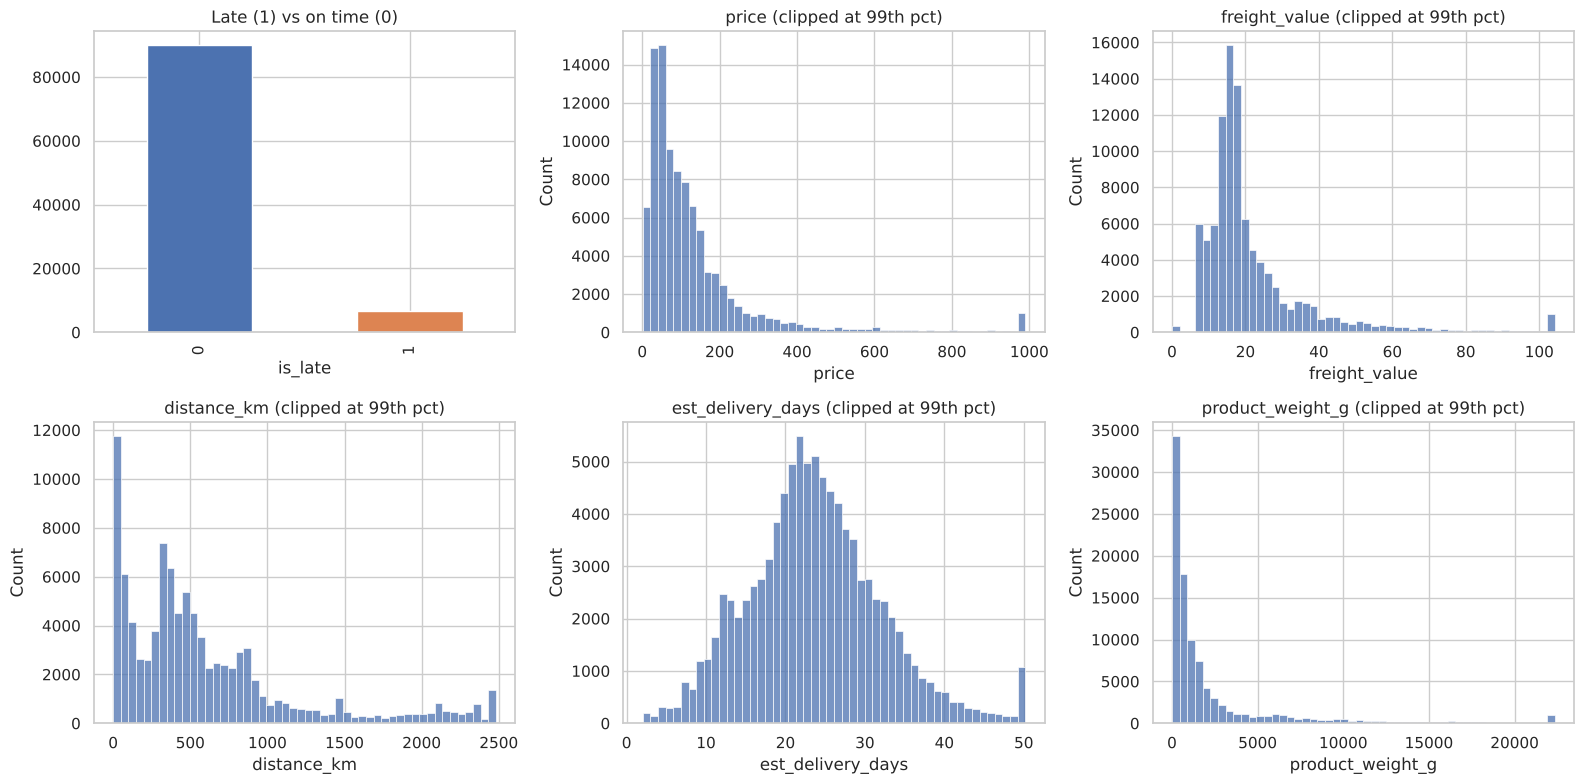

In [7]:
# Univariate: target and key numeric features
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
df.is_late.value_counts().plot.bar(ax=axes[0, 0], color=["#4c72b0", "#dd8452"])
axes[0, 0].set_title("Late (1) vs on time (0)")
for ax, col in zip(axes.flat[1:], ["price", "freight_value", "distance_km", "est_delivery_days", "product_weight_g"]):
    sns.histplot(df[col].dropna().clip(upper=df[col].quantile(0.99)), bins=50, ax=ax)
    ax.set_title(col + " (clipped at 99th pct)")
plt.tight_layout()
plt.show()

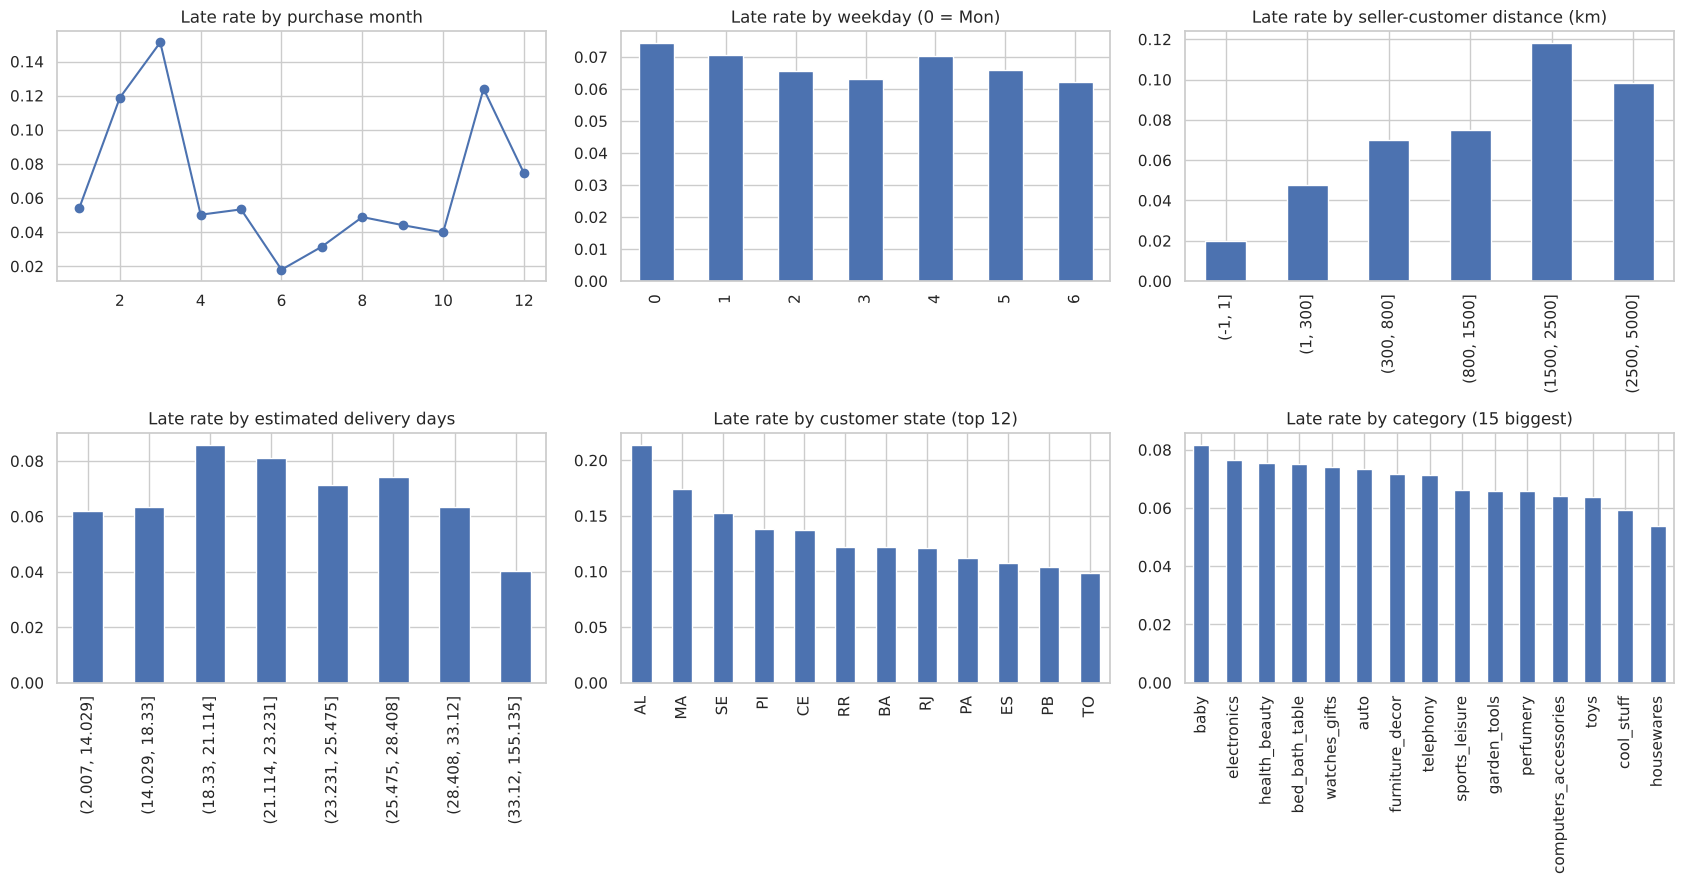

In [8]:
# Bivariate: late rate by key drivers
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

df.groupby("purchase_month").is_late.mean().plot(marker="o", ax=axes[0, 0], title="Late rate by purchase month")
df.groupby("purchase_dow").is_late.mean().plot.bar(ax=axes[0, 1], title="Late rate by weekday (0 = Mon)")
df.groupby(pd.cut(df.distance_km, [-1, 1, 300, 800, 1500, 2500, 5000]), observed=True).is_late.mean() \
    .plot.bar(ax=axes[0, 2], title="Late rate by seller-customer distance (km)")
df.groupby(pd.qcut(df.est_delivery_days, 8, duplicates="drop"), observed=True).is_late.mean() \
    .plot.bar(ax=axes[1, 0], title="Late rate by estimated delivery days")
df.groupby("customer_state").is_late.mean().sort_values(ascending=False).head(12) \
    .plot.bar(ax=axes[1, 1], title="Late rate by customer state (top 12)")
top_cat = df.product_category.value_counts().head(15).index
df[df.product_category.isin(top_cat)].groupby("product_category").is_late.mean().sort_values(ascending=False) \
    .plot.bar(ax=axes[1, 2], title="Late rate by category (15 biggest)")
for ax in axes.flat:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

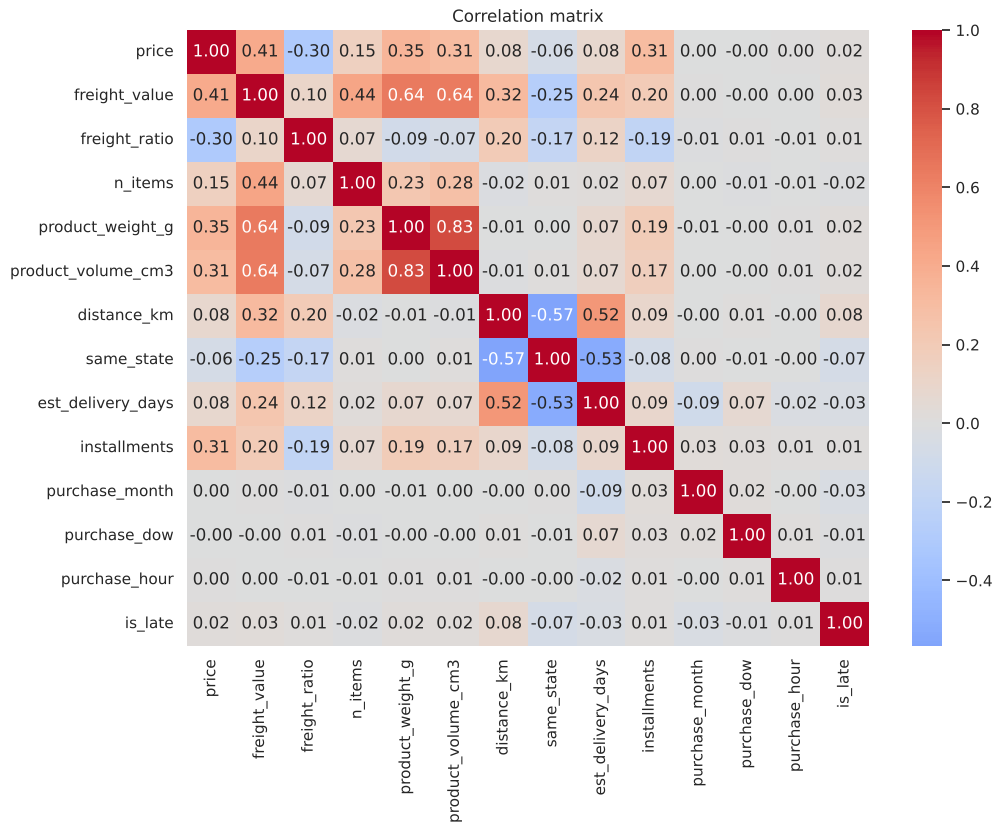

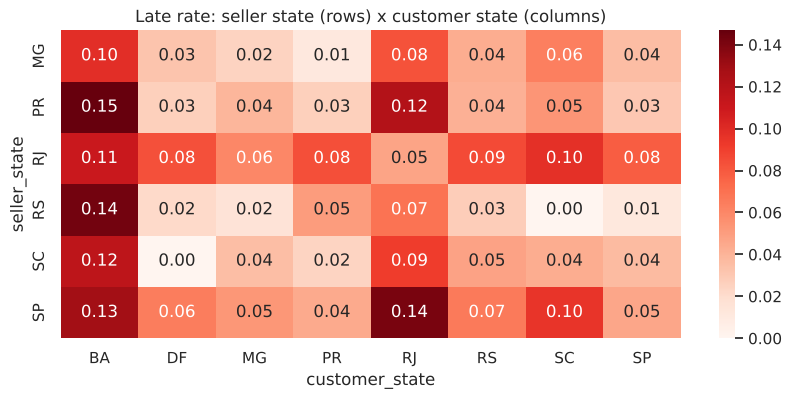

In [9]:
# Multivariate: correlations among numeric features and with the target
plt.figure(figsize=(11, 8))
sns.heatmap(df[NUM_FEATURES + ["is_late"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

# seller state x customer state late-rate heatmap (biggest states only)
big = df.seller_state.value_counts().head(6).index
big_c = df.customer_state.value_counts().head(8).index
pivot = (df[df.seller_state.isin(big) & df.customer_state.isin(big_c)]
         .pivot_table(index="seller_state", columns="customer_state", values="is_late", aggfunc="mean"))
plt.figure(figsize=(10, 4))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="Reds")
plt.title("Late rate: seller state (rows) x customer state (columns)")
plt.show()

### EDA insights
1. **Strong class imbalance:** only 6.8% of the 96,470 delivered orders arrived late. Predicting "on time" for everything is 93% accurate, so accuracy is useless here and we judge models by PR-AUC and recall.
2. **Timing is the biggest driver:** the late rate was 12.4% in Nov 2017 (Black Friday period), 14.1% in Feb 2018 and 19.0% in Mar 2018, versus 1.8% when averaging all Junes. Congested periods explain much of the lateness.
3. **Distance and region matter:** using real zip-code coordinates, orders under 300 km were late 4.8% of the time, rising steadily to 11.8% at 1,500-2,500 km. Orders crossing state lines were late 8.0% versus 4.5% within a state. North-eastern states are worst (AL 21.4%, MA 17.4%, SE 15.2%) versus 4.5% for SP.
4. **A longer promised delivery time is not a simple safety margin:** the late rate by quartile of estimated delivery days is 6.3%, 8.4%, 7.3% and 5.2% (shortest to longest), so the relationship is non-linear.
5. **A few sellers and categories stand out:** 10 of the 621 sellers with at least 30 orders were late more than 20% of the time (worst 34.3%). Among categories with at least 300 orders, audio (11.9%) and home_confort (9.5%) are the latest.


## 4. Preprocessing and train/test split
We split **before** fitting anything. All imputing, scaling and encoding live inside a scikit-learn `Pipeline`, so the test set never influences the preprocessing.

In [10]:
X = df[FEATURES]
y = df.is_late
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape, f"late rate train {y_train.mean():.3f} / test {y_test.mean():.3f}")

numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
categorical_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=30, sparse_output=False))])
preprocess = ColumnTransformer([("num", numeric_pipe, NUM_FEATURES), ("cat", categorical_pipe, CAT_FEATURES)])


def make_pipeline(model):
    return Pipeline([("prep", preprocess), ("model", model)])

(77176, 17) (19294, 17) late rate train 0.068 / test 0.068


## 5. Modeling: baseline + three algorithms (5-fold cross-validation on the training set)

In [11]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight="balanced_subsample",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
}
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall", "precision": "precision"}

rows = []
for name, model in candidates.items():
    res = cross_validate(make_pipeline(model), X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    rows.append({"model": name, **{k: res[f"test_{k}"].mean() for k in scoring}})
cv_results = pd.DataFrame(rows).set_index("model").round(3)
cv_results

,roc_auc,pr_auc,recall,precision
model,,,,
Baseline (majority class),0.500,0.068,0.000,0.000
Logistic Regression,0.703,0.155,0.629,0.122
Random Forest,0.773,0.251,0.297,0.311
Gradient Boosting,0.779,0.250,0.662,0.169


## 6. Hyperparameter tuning (training data only)

In [12]:
search_spaces = {
    "Random Forest": (
        make_pipeline(RandomForestClassifier(class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)),
        {"model__n_estimators": [150, 250, 400], "model__max_depth": [8, 12, 16, None],
         "model__min_samples_leaf": [3, 5, 10, 20], "model__max_features": ["sqrt", 0.3]},
    ),
    "Gradient Boosting": (
        make_pipeline(HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
        {"model__learning_rate": [0.03, 0.05, 0.1], "model__max_depth": [3, 5, 8, None],
         "model__max_leaf_nodes": [15, 31, 63], "model__min_samples_leaf": [20, 50, 100],
         "model__l2_regularization": [0.0, 1.0, 10.0]},
    ),
}

tuned = {}
for name, (pipe, grid) in search_spaces.items():
    search = RandomizedSearchCV(pipe, grid, n_iter=12, scoring="average_precision",
                                cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                                random_state=RANDOM_STATE, n_jobs=1, verbose=0)
    search.fit(X_train, y_train)
    tuned[name] = search
    print(f"{name}: best CV PR-AUC {search.best_score_:.4f}\n  {search.best_params_}")

best_name = max(tuned, key=lambda n: tuned[n].best_score_)
best_model = tuned[best_name].best_estimator_
print("\nBest model:", best_name)

Random Forest: best CV PR-AUC 0.2520
  {'model__n_estimators': 250, 'model__min_samples_leaf': 20, 'model__max_features': 0.3, 'model__max_depth': None}


Gradient Boosting: best CV PR-AUC 0.2478
  {'model__min_samples_leaf': 100, 'model__max_leaf_nodes': 63, 'model__max_depth': None, 'model__learning_rate': 0.05, 'model__l2_regularization': 1.0}

Best model: Random Forest


## 7. Evaluation on the untouched test set
The decision threshold is chosen **using only training data** (cross-validated predicted probabilities): the highest-precision threshold that still reaches the target recall.

In [13]:
train_proba = cross_val_predict(best_model, X_train, y_train, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, train_proba)
ok = np.where(rec[:-1] >= TARGET_RECALL)[0]
THRESHOLD = float(thr[ok[np.argmax(prec[:-1][ok])]]) if len(ok) else 0.5
print(f"Chosen threshold: {THRESHOLD:.3f} (target recall {TARGET_RECALL:.0%} on training CV)")


def score(model, X_, y_, threshold):
    p = model.predict_proba(X_)[:, 1]
    pred = (p >= threshold).astype(int)
    return {"roc_auc": roc_auc_score(y_, p), "pr_auc": average_precision_score(y_, p),
            "recall": recall_score(y_, pred), "precision": precision_score(y_, pred, zero_division=0),
            "f1": f1_score(y_, pred)}, p, pred


results = {}
for name, model in candidates.items():
    fitted = make_pipeline(model).fit(X_train, y_train)
    results[name], _, _ = score(fitted, X_test, y_test, 0.5)
for name, search in tuned.items():
    results[f"{name} (tuned)"], _, _ = score(search.best_estimator_, X_test, y_test, 0.5)
results[f"{best_name} (tuned, chosen threshold)"], test_proba, test_pred = score(best_model, X_test, y_test, THRESHOLD)

test_results = pd.DataFrame(results).T.round(3)
test_results

Chosen threshold: 0.388 (target recall 60% on training CV)


,roc_auc,pr_auc,recall,precision,f1
Baseline (majority class),0.500,0.068,0.000,0.000,0.000
Logistic Regression,0.710,0.158,0.628,0.122,0.204
Random Forest,0.788,0.254,0.295,0.314,0.304
Gradient Boosting,0.795,0.256,0.683,0.172,0.274
Random Forest (tuned),0.790,0.258,0.463,0.247,0.322
Gradient Boosting (tuned),0.793,0.255,0.662,0.174,0.276
"Random Forest (tuned, chosen threshold)",0.790,0.258,0.612,0.195,0.296


              precision    recall  f1-score   support

     on time       0.97      0.82      0.89     17987
        late       0.20      0.61      0.30      1307

    accuracy                           0.80     19294
   macro avg       0.58      0.71      0.59     19294
weighted avg       0.91      0.80      0.85     19294



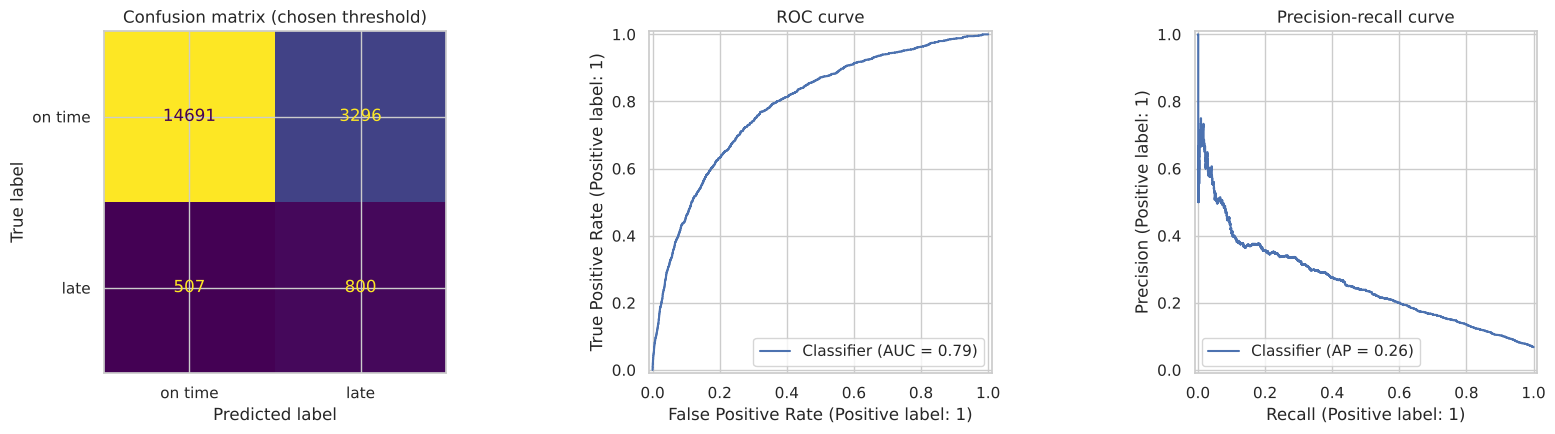

In [14]:
print(classification_report(y_test, test_pred, target_names=["on time", "late"]))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["on time", "late"], ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (chosen threshold)")
RocCurveDisplay.from_predictions(y_test, test_proba, ax=axes[1])
axes[1].set_title("ROC curve")
PrecisionRecallDisplay.from_predictions(y_test, test_proba, ax=axes[2])
axes[2].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

### Error analysis

In [15]:
err = X_test.copy()
err["is_late"] = y_test.values
err["pred"] = test_pred
err["error"] = np.where((err.is_late == 1) & (err.pred == 0), "missed late",
                        np.where((err.is_late == 0) & (err.pred == 1), "false alarm", "correct"))
print(err.error.value_counts())

by_state = err.groupby("customer_state").apply(
    lambda g: pd.Series({"orders": len(g), "late_rate": g.is_late.mean(),
                         "recall": g.loc[g.is_late == 1, "pred"].mean() if (g.is_late == 1).any() else np.nan}))
display(by_state[by_state.orders >= 100].sort_values("recall").head(8))

by_dist = err.groupby(pd.cut(err.distance_km, [-1, 1, 300, 800, 1500, 2500, 5000]), observed=True).apply(
    lambda g: pd.Series({"orders": len(g), "late_rate": g.is_late.mean(),
                         "recall": g.loc[g.is_late == 1, "pred"].mean() if (g.is_late == 1).any() else np.nan}))
display(by_dist)

error
correct        15491
false alarm     3296
missed late      507
Name: count, dtype: int64


,orders,late_rate,recall
customer_state,,,
SP,8103.0,0.044305,0.337047
RS,1066.0,0.056285,0.516667
MG,2312.0,0.045415,0.523810
MS,149.0,0.114094,0.529412
PR,980.0,0.037755,0.540541
SC,650.0,0.081538,0.584906
PE,328.0,0.121951,0.600000
PB,115.0,0.113043,0.615385


,orders,late_rate,recall
distance_km,,,
"(-1, 1]",13.0,0.000000,NaN
"(1, 300]",6232.0,0.046694,0.371134
"(300, 800]",8132.0,0.070093,0.635088
"(800, 1500]",3136.0,0.072385,0.669604
"(1500, 2500]",1610.0,0.123602,0.804020
"(2500, 5000]",171.0,0.116959,0.900000


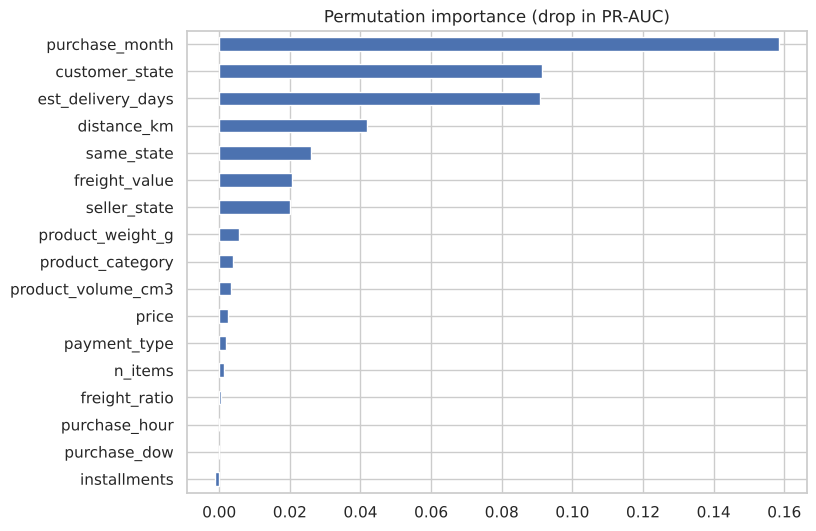

In [16]:
# Which features matter most? (permutation importance on a test sample)
sample = X_test.sample(min(8000, len(X_test)), random_state=RANDOM_STATE)
perm = permutation_importance(best_model, sample, y_test.loc[sample.index], scoring="average_precision",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
imp.plot.barh(figsize=(8, 6), title="Permutation importance (drop in PR-AUC)")
plt.show()

In [17]:
# Robustness check: train on older orders, test on the newest 20% (the future, like real use)
order_time = df.order_purchase_timestamp
cut = order_time.quantile(0.8)
tr, te = df[order_time <= cut], df[order_time > cut]
m = make_pipeline(HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)).fit(tr[FEATURES], tr.is_late)
p = m.predict_proba(te[FEATURES])[:, 1]
print(f"Time-based split: ROC-AUC {roc_auc_score(te.is_late, p):.3f}, PR-AUC {average_precision_score(te.is_late, p):.3f} "
      f"(late rate in newest 20%: {te.is_late.mean():.3f})")

Time-based split: ROC-AUC 0.696, PR-AUC 0.070 (late rate in newest 20%: 0.035)


## 8. Business insight and limitations
**What the model does.** On the untouched test set (19,294 orders, 6.8% late) the tuned Random Forest at the chosen threshold (0.39) catches **61% of late orders** (recall 0.61) with **19.5% precision** and ROC-AUC 0.79 / PR-AUC 0.26. It flags about 21% of orders as high risk; roughly one in five of those is truly late, about **2.9 times** the 6.8% base rate. Gradient Boosting performed almost identically (CV PR-AUC 0.2478 vs 0.2520), so the choice between them is a tie. Both clearly beat the baseline and Logistic Regression (PR-AUC 0.16).

**What drives lateness.** Permutation importance ranks purchase month first, then customer state, estimated delivery days and seller-customer distance.

**Did exact zip-code distance help?** We first built the model with distance between state capitals, then re-ran it with real zip-code coordinates from the geolocation table (over 99% of orders matched; the rest fall back to the state capital). Performance was essentially unchanged (test PR-AUC 0.258 vs 0.260, ROC-AUC 0.790 vs 0.791, same recall and precision at the threshold). State and delivery-time features already carry most of the geographic signal, and timing dominates. The more precise distance is still useful for the app and for the error analysis below.

**What the company should do.**
- Warn customers and prioritise carrier follow-up for HIGH-risk orders, and do it especially in peak periods (Black Friday weeks and Q1).
- Give longer, more honest delivery estimates on long-distance and north-eastern routes, where late rates reach 12-21%.
- Review the 10 sellers with over 20% late rate (seller page in the app).
- Late delivery hurts satisfaction: 62.4% of late orders got a 1-2 star review versus 9.2% of on-time orders (average score 2.27 vs 4.29), which is the business case for acting.

**Limitations.**
- **The model does not hold up well over time.** When trained on older orders and tested on the newest 20% (from late May 2018), ROC-AUC drops to 0.70 and PR-AUC to 0.07, though that period had only a 3.5% late rate (vs 7.6% before). Much of the signal is tied to specific 2017-2018 congestion periods, so it should be retrained regularly and monitored.
- It misses many late orders inside SP and on short routes (recall about 34% for SP customers and 37% under 300 km), where lateness is rarer and harder to predict; it works best on long routes (recall about 80% at 1,500-2,500 km).
- Distance is a straight line between zip-prefix areas, not road distance or the carrier's real route, and the data covers only 2016-2018 in Brazil.
- With precision under 20%, most alerts are false alarms, so actions should be cheap (a proactive message), not costly (re-shipping).


## 9. Save the pipeline and app files

In [18]:
joblib.dump(best_model, ART_DIR / "model.joblib", compress=3)

# zip prefix -> coordinates, so the app can compute real distances (about 19K rows, under 1 MB)
zip_coords.round(5).reset_index().rename(columns={"geolocation_zip_code_prefix": "zip_prefix"}) \
    .to_csv(ART_DIR / "zip_coords.csv", index=False)

seller_stats = (df.groupby("seller_id").agg(n_orders=("is_late", "size"), late_rate=("is_late", "mean"),
                                            seller_state=("seller_state", "first")).reset_index())
seller_stats.to_csv(ART_DIR / "seller_stats.csv", index=False)

state_list = sorted(state_centroids.index.intersection(
    pd.concat([df.seller_state, df.customer_state]).dropna().unique()))
meta = {
    "features": FEATURES,
    "threshold": THRESHOLD,
    "best_model": best_name,
    "platform_late_rate": float(df.is_late.mean()),
    "categories": df.product_category.value_counts().index.tolist(),
    "states": state_list,
    "payment_types": sorted(df.payment_type.dropna().unique().tolist()),
    "state_centroids": {k: [float(v["lat"]), float(v["lng"])] for k, v in state_centroids.loc[state_list].iterrows()},
    "defaults": {"price": float(df.price.median()), "freight_value": float(df.freight_value.median()),
                 "product_weight_g": float(df.product_weight_g.median()),
                 "product_volume_cm3": float(df.product_volume_cm3.median()),
                 "est_delivery_days": float(df.est_delivery_days.median())},
    "test_metrics": {k: round(float(v), 4) for k, v in results[f"{best_name} (tuned, chosen threshold)"].items()},
}
(ART_DIR / "meta.json").write_text(json.dumps(meta, indent=2))
print("Saved:", sorted(p.name for p in ART_DIR.iterdir()))

Saved: ['meta.json', 'model.joblib', 'seller_stats.csv', 'zip_coords.csv']


## 10. (Stretch) How much does late delivery hurt satisfaction?
Review scores are known only *after* delivery, so they are used here for analysis only, never as a model feature.

         mean  count
is_late             
0        4.29  89443
1        2.27   6381


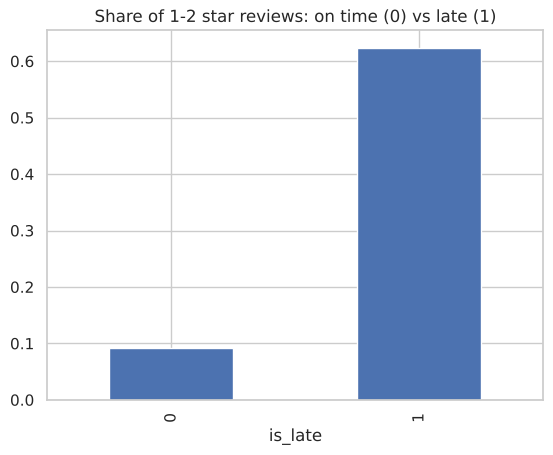

In [19]:
rv = reviews.groupby("order_id").review_score.mean().rename("review_score")
tmp = df[["order_id", "is_late"]].merge(rv, on="order_id", how="left").dropna()
print(tmp.groupby("is_late").review_score.agg(["mean", "count"]).round(2))
tmp.assign(low_review=(tmp.review_score <= 2)).groupby("is_late").low_review.mean().plot.bar(
    title="Share of 1-2 star reviews: on time (0) vs late (1)")
plt.show()